# code_015 · Statistical comparisons and resampling

**Book:** Chapter 3, section 3.4. **Purpose:** an independent probability/statistics laboratory with synthetic populations and declared measurement models. No numerical result is evidence of structural safety, an empirical causal effect or production reliability.

Use the repository [quickstart](../README.md), select the [pinned environment](../requirements-lock.txt), restart and run every cell. Reference target: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, CPU only on macOS ARM64. All inputs, generators and helper definitions are here. Normal runs require no network, data files, API keys, GPU or private imports. Allow a minute for execution and 30–60 minutes for interpretation/exercises. Actual versions and time appear below and in [run evidence](../CHAPTER_03_EXECUTION.md).

Read predictions before output. Sampling assumptions, priors, numerical simulation budgets and decision margins have different roles; they are not all model hyperparameters. These are scoped concept laboratories, not full estimator-constructor guides. The [traceability guide](../CHAPTER_03_GUIDE.md) maps mechanisms and exercises, and the [stable registry](../CODE_EXAMPLES.md#code_015) preserves this ID. Synthetic algebra/population checks need no learned train/test split; any fitted prediction experiment below states its calibration and assessment boundaries.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import stats,special
from IPython.display import display
START=time.perf_counter();SEED=315
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 315


<a id="contract"></a>
## Fixed predictors, independent assessment buildings

We compare absolute deflection errors in mm from two *fixed* predictors on 40 independent synthetic buildings, 30 readings each. No model is fitted or selected on these assessment outcomes. Positive d=error_A-error_B favors B. The target is the equal-building population mean difference. Cluster sizes are equal here; unequal sizes require an explicit equal-building or equal-reading estimand. A predeclared useful improvement is .05 mm.

Construct d=.08+building_effect+reading_noise, with independent building effects sd .18 mm and conditional reading noise sd .03 mm. The true population contrast is .08 mm under this simulator. Positive individual absolute errors are supplied consistently with d. This is mechanism isolation, not an empirical predictor leaderboard.

**Predict:** why should all readings in a sampled building move together in a bootstrap replicate? Does a bootstrap of these errors include variation from refitting a training algorithm?


In [2]:
G,m=40,30;true_delta=.08;practical_margin=.05
building=rng.normal(0,.18,G);d=true_delta+building[:,None]+rng.normal(0,.03,(G,m))
error_A=1.+.1*np.abs(rng.normal(size=(G,m)));error_B=error_A-d
assert np.all(error_B>0) and np.allclose(error_A-error_B,d)
building_diff=d.mean(1);estimate=building_diff.mean()
assert np.isclose(estimate,d.mean())
display(pd.DataFrame({'building_id':np.arange(G),'paired_difference_mm':building_diff}).head(10))
RESULTS['mean_paired_difference_mm']=float(estimate);RESULTS['true_simulator_difference_mm']=true_delta


,building_id,paired_difference_mm
0,0,0.186465
1,1,0.081742
2,2,-0.090409
3,3,0.232591
4,4,0.390105
5,5,0.186958
6,6,-0.177442
7,7,-0.316002
8,8,0.050434
9,9,-0.219125


<a id="bootstrap"></a>
## Preserve the independent unit and pairing

A building bootstrap samples G building IDs with replacement. Since the statistic averages within each equally weighted building, resampling the building differences is equivalent to carrying all their paired rows. The deliberately wrong row bootstrap treats 1200 dependent readings as independent. We use a basic percentile construction for transparency, without claiming exact coverage; skew, few groups, boundaries and selection can make it fail. Increasing B reduces Monte Carlo noise, not sampling uncertainty.

**Predict:** which bootstrap distribution will be wider under this generating model? What would happen if within-building differences were truly independent instead?


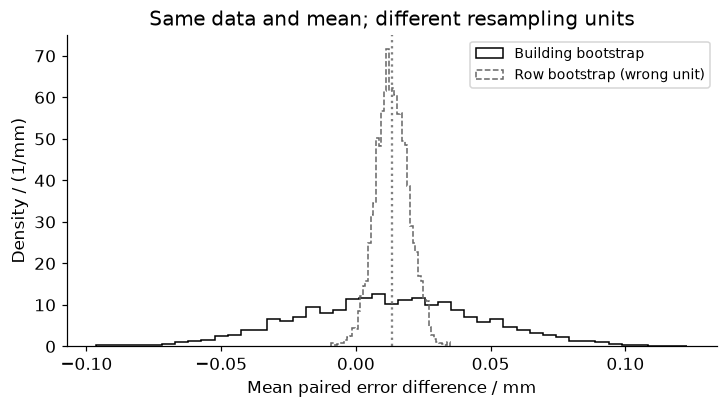

Cluster interval [mm]: [-0.05461242  0.08022953] row interval [mm]: [0.00154081 0.02581501] SE ratio: 5.576033578958443


In [3]:
B=4000;boot_rng=np.random.default_rng(SEED+1000)
building_indices=boot_rng.integers(0,G,(B,G));cluster=building_diff[building_indices].mean(1)
flat=d.ravel();row_indices=boot_rng.integers(0,len(flat),(B,len(flat)));row=flat[row_indices].mean(1)
ci_cluster=np.quantile(cluster,[.025,.975]);ci_row=np.quantile(row,[.025,.975])
se_cluster=cluster.std(ddof=1);se_row=row.std(ddof=1)
assert se_cluster>3*se_row
assert np.isclose(se_cluster,building_diff.std(ddof=1)/np.sqrt(G),rtol=.1)
# Same sampled building IDs preserve the paired predictor comparison.
paired_check=(error_A.mean(1)[building_indices]-error_B.mean(1)[building_indices]).mean(1)
assert np.allclose(paired_check,cluster)
fig,ax=plt.subplots(figsize=(6.5,3.6));ax.hist(cluster,bins=45,density=True,histtype='step',color='black',label='Building bootstrap')
ax.hist(row,bins=45,density=True,histtype='step',color='.4',ls='--',label='Row bootstrap (wrong unit)');ax.axvline(estimate,color='.5',ls=':')
ax.set(xlabel='Mean paired error difference / mm',ylabel='Density / (1/mm)',title='Same data and mean; different resampling units');ax.legend(fontsize=9);plt.show()
print('Cluster interval [mm]:',ci_cluster,'row interval [mm]:',ci_row,'SE ratio:',se_cluster/se_row)
RESULTS['building_bootstrap_95pct_interval_mm']=ci_cluster.tolist();RESULTS['row_bootstrap_95pct_interval_mm']=ci_row.tolist();RESULTS['bootstrap_SE_ratio']=float(se_cluster/se_row)


<a id="effect-test"></a>
## Magnitude, practical importance and a conditional test

Report the effect estimate and interval relative to zero and the predeclared .05 mm margin. Do not turn the fraction of bootstrap replicates above the margin into an unqualified posterior probability.

A two-sided paired sign-flip test is valid under independent differences symmetric around zero under the null (or an appropriate randomization justification). Mean equality alone is insufficient. The simulator's centered null model is normal and symmetric. We explicitly disclose that assumption; arbitrary real building errors may violate it. Monte Carlo signs use a fixed budget and plus-one tail calculation.

**Predict:** can a statistically detectable difference still be too small to matter? Does the p-value give the probability that the null hypothesis is true?


In [4]:
print('Estimate [mm]:',estimate,'practical margin [mm]:',practical_margin)
print('Interval entirely above zero:',bool(ci_cluster[0]>0),'entirely above practical margin:',bool(ci_cluster[0]>practical_margin))
R=9999;test_rng=np.random.default_rng(SEED+2000);signs=test_rng.choice([-1.,1.],size=(R,G))
null_statistics=(signs*building_diff).mean(1)
p_value=(1+np.count_nonzero(np.abs(null_statistics)>=abs(estimate)))/(R+1)
assert 0<p_value<=1 and np.isclose(np.mean(building_diff),estimate)
print('Two-sided sign-flip Monte Carlo p-value (symmetry assumption):',p_value)
RESULTS['practical_margin_mm']=practical_margin;RESULTS['sign_flip_p_value']=float(p_value)


Estimate [mm]: 0.013391007544116467 practical margin [mm]: 0.05
Interval entirely above zero: False entirely above practical margin: False
Two-sided sign-flip Monte Carlo p-value (symmetry assumption): 0.6998


<a id="multiplicity"></a>
## A search produces apparently favorable null comparisons

Simulate 20 independent candidates, each tested against zero using 30 independent normal differences under a true null. The ordinary t-test is valid under this declared normal model. Repeat the entire candidate search 2000 times. The chance of at least one level-.05 rejection under independent tests is 1-.95^20; a Bonferroni threshold .05/20 bounds familywise error by .05 for valid tests even without independence. These are null procedure checks, not a search for the best real predictor.

**Predict:** how often will a search return a seemingly significant candidate although every null is true? Does reporting only the selected candidate's usual interval include this selection uncertainty?


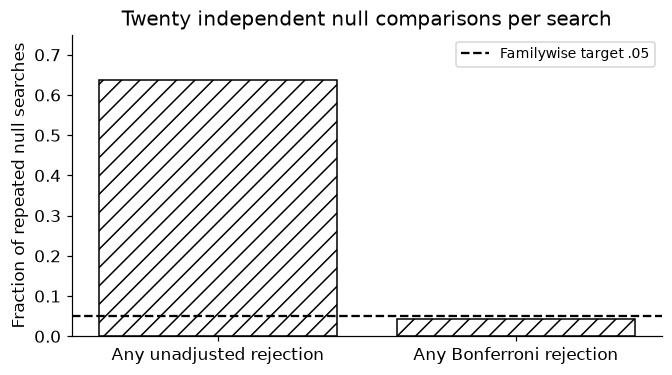

Observed familywise rates: 0.6365 0.044 unadjusted theory: 0.6415140775914581


In [5]:
alpha=.05;K=20;replications=2000;sample_size=30
null_rng=np.random.default_rng(SEED+3000);null_data=null_rng.normal(size=(replications,K,sample_size))
pvalues=stats.ttest_1samp(null_data,0,axis=-1).pvalue
any_raw=(pvalues<alpha).any(1).mean();any_adjusted=(pvalues<alpha/K).any(1).mean();theory=1-(1-alpha)**K
assert pvalues.shape==(replications,K) and np.all((pvalues>=0)&(pvalues<=1))
assert abs(any_raw-theory)<.04 and any_adjusted<any_raw
fig,ax=plt.subplots(figsize=(6,3.3));ax.bar(['Any unadjusted rejection','Any Bonferroni rejection'],[any_raw,any_adjusted],color='white',edgecolor='black',hatch='//')
ax.axhline(alpha,color='black',ls='--',label='Familywise target .05');ax.set(ylabel='Fraction of repeated null searches',ylim=(0,.75),title='Twenty independent null comparisons per search');ax.legend(fontsize=9);plt.show()
print('Observed familywise rates:',any_raw,any_adjusted,'unadjusted theory:',theory)
RESULTS['unadjusted_familywise_rate']=float(any_raw);RESULTS['bonferroni_familywise_rate']=float(any_adjusted);RESULTS['independent_null_familywise_theory']=float(theory)


<a id="exercises"></a>
## Exercises and optional hints

1. Introduce unequal numbers of readings per building. Compare equal-building and equal-reading estimands before choosing a bootstrap statistic.
2. Remove the building effect while preserving row noise. Explain why the bootstrap-unit gap narrows.
3. Resample A and B separately. Explain the loss of pairing; do not assume its width must change in one universal direction.
4. Replace symmetric building effects with skewed effects centered at zero. Investigate the sign-flip assumption instead of claiming mean-zero is sufficient.
5. Increase bootstrap B while keeping 40 buildings fixed. Separate simulation precision from scientific sample size.
6. Define a new experiment comparing training algorithms, including refitting and selection. Describe what this fixed-predictor error bootstrap leaves out.

**Hints:** a confidence level concerns a procedure's repeated coverage under assumptions. Percentile bootstrap is transparent but not universally calibrated. A p-value is a null tail probability, not a posterior null probability or practical effect size. Bonferroni needs valid individual tests and a declared family, not independence; adaptive selective reporting still requires care.

**Troubleshooting:** preserve building IDs and case pairing; never inflate independent sample size using bootstrap replicates. Docs: [bootstrap pairing](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html) and [one-sample t-test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html). The explicit manual grouped bootstrap above avoids silently treating a library's default row axis as the scientific unit.


In [6]:
summary={'example_id':'code_015','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['paired equal-building estimand', 'cluster versus row bootstrap', 'percentile interval limitations', 'practical effect size', 'assumption-dependent sign-flip test', 'multiple comparisons and Bonferroni'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["paired equal-building estimand", "cluster versus row bootstrap", "percentile interval limitations", "practical effect size", "assumption-dependent sign-flip test", "multiple comparisons and Bonferroni"], "elapsed_seconds": 0.176, "example_id": "code_015", "hardware": "Darwin arm64 CPU", "results": {"bonferroni_familywise_rate": 0.044, "bootstrap_SE_ratio": 5.576033578958443, "building_bootstrap_95pct_interval_mm": [-0.05461242135776273, 0.08022953137794857], "independent_null_familywise_theory": 0.6415140775914581, "mean_paired_difference_mm": 0.013391007544116467, "practical_margin_mm": 0.05, "row_bootstrap_95pct_interval_mm": [0.0015408131498804505, 0.025815005344921142], "sign_flip_p_value": 0.6998, "true_simulator_difference_mm": 0.08, "unadjusted_familywise_rate": 0.6365}, "seed": 315, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
